Mounted at /content/drive
Starting training pipeline...
Using device: cuda

1. Loading data...

Loading 4 file(s)

[File 1/4]
Parsing file: /content/drive/MyDrive/443 project/443/RNA-577-Train.fasta
  ✓ Parsed 577 sequences
  ✓ Added 577 sequences from /content/drive/MyDrive/443 project/443/RNA-577-Train.fasta

[File 2/4]
Parsing file: /content/drive/MyDrive/443 project/443/RNA-142-Test.fasta
  ✓ Parsed 142 sequences
  ✓ Added 142 sequences from /content/drive/MyDrive/443 project/443/RNA-142-Test.fasta

[File 3/4]
Parsing file: /content/drive/MyDrive/443 project/443/DNA-735-Train.fasta
  ✓ Parsed 735 sequences
  ✓ Added 735 sequences from /content/drive/MyDrive/443 project/443/DNA-735-Train.fasta

[File 4/4]
Parsing file: /content/drive/MyDrive/443 project/443/DNA-180-Test.fasta
  ✓ Parsed 180 sequences
  ✓ Added 180 sequences from /content/drive/MyDrive/443 project/443/DNA-180-Test.fasta

Total sequences loaded: 1634
Total residues: 481252
Binding sites: 45911 / 481252 (9.54%)


Datas

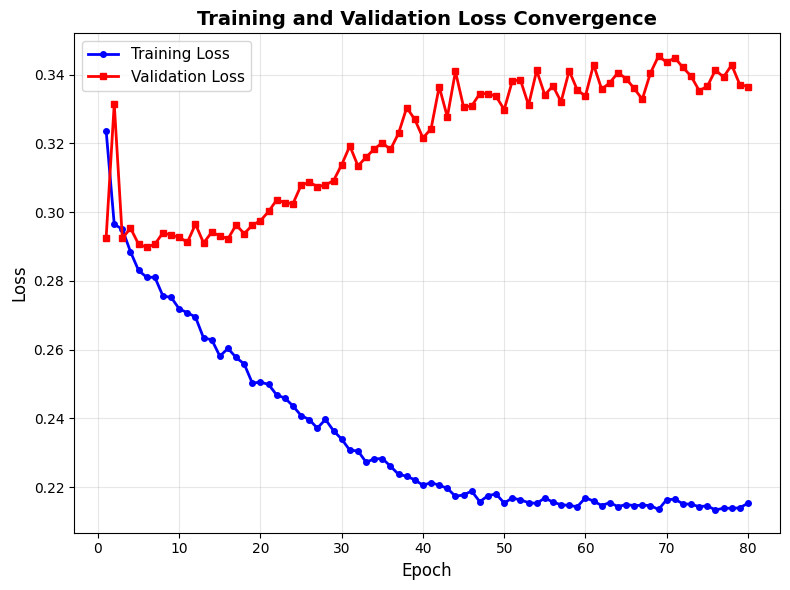


Loading best model for evaluation...

CNN Evaluation Results
MCC            : 0.1346
TDR (Recall)   : 0.0317
PDR (FPR)      : 0.0015
AUC            : 0.7340
AUPR           : 0.2738

Generating TDR-PDR curve...


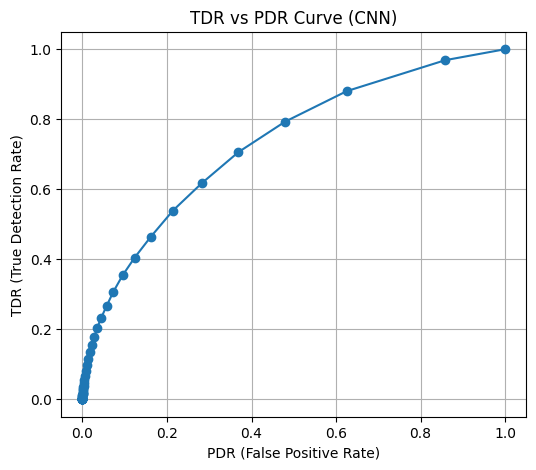


Generating 3D TDR-PDR-MCC plot...


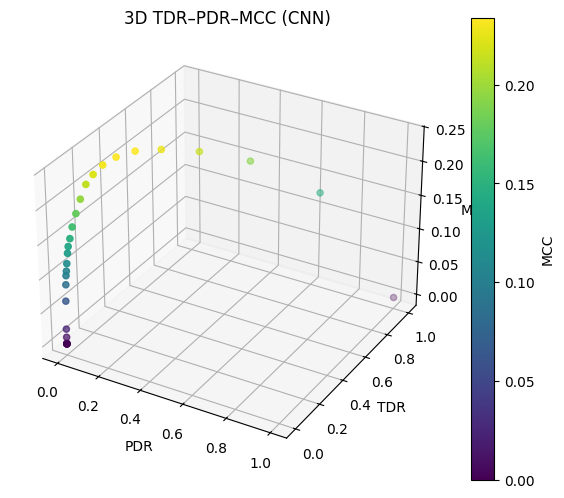


All done!


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
from sklearn.model_selection import train_test_split
import ast
import matplotlib.pyplot as plt
from sklearn.metrics import (
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
from mpl_toolkits.mplot3d import Axes3D

# ===========================
# 1. DATA PREPROCESSING
# ===========================

from google.colab import drive
drive.mount('/content/drive')

file_paths = [
    '/content/drive/MyDrive/443 project/443/RNA-577-Train.fasta',
    '/content/drive/MyDrive/443 project/443/RNA-142-Test.fasta',
    '/content/drive/MyDrive/443 project/443/DNA-735-Train.fasta',
    '/content/drive/MyDrive/443 project/443/DNA-180-Test.fasta'
]

class ProteinDataProcessor:
    """Processes protein/DNA/RNA sequence data with labels"""

    def __init__(self):
        self.aa_vocab = {
            'A': 0, 'C': 1, 'D': 2, 'E': 3, 'F': 4, 'G': 5, 'H': 6, 'I': 7,
            'K': 8, 'L': 9, 'M': 10, 'N': 11, 'P': 12, 'Q': 13, 'R': 14,
            'S': 15, 'T': 16, 'V': 17, 'W': 18, 'Y': 19, 'X': 20
        }
        self.vocab_size = len(self.aa_vocab)

    def parse_data_file(self, file_path, verbose=True):
        sequences = []
        labels = []
        seq_ids = []

        if verbose:
            print(f"Parsing file: {file_path}")

        with open(file_path, 'r') as f:
            lines = f.readlines()

        i = 0
        total_lines = len(lines)
        parsed_count = 0
        skipped_count = 0

        while i < total_lines:
            line = lines[i].strip()

            if line.startswith('>'):
                seq_id = line[1:].strip()
                i += 1

                if i < total_lines:
                    sequence = lines[i].strip()
                    i += 1

                    if i < total_lines:
                        label_str = lines[i].strip()

                        try:
                            label_list = ast.literal_eval(label_str)

                            if len(sequence) == len(label_list):
                                sequences.append(sequence)
                                labels.append(label_list)
                                seq_ids.append(seq_id)
                                parsed_count += 1

                                if verbose and parsed_count % 1000 == 0:
                                    print(f"  Parsed {parsed_count} sequences...")
                            else:
                                skipped_count += 1
                                if verbose and skipped_count == 1:
                                    print(f"  Warning: Skipping sequences with mismatched lengths")
                        except (SyntaxError, ValueError) as e:
                            skipped_count += 1
                            if verbose and skipped_count <= 5:
                                print(f"  Error parsing labels: {e}")

                        i += 1
            else:
                i += 1

        if verbose:
            print(f"  ✓ Parsed {parsed_count} sequences")
            if skipped_count > 0:
                print(f"  ⚠ Skipped {skipped_count} invalid sequences")

        return sequences, labels, seq_ids

    def load_multiple_files(self, file_paths, verbose=True):
        if isinstance(file_paths, str):
            file_paths = [file_paths]

        all_sequences = []
        all_labels = []
        all_seq_ids = []

        print(f"\n{'='*60}")
        print(f"Loading {len(file_paths)} file(s)")
        print(f"{'='*60}")

        for idx, file_path in enumerate(file_paths, 1):
            print(f"\n[File {idx}/{len(file_paths)}]")

            try:
                sequences, labels, seq_ids = self.parse_data_file(file_path, verbose=verbose)

                all_sequences.extend(sequences)
                all_labels.extend(labels)
                all_seq_ids.extend(seq_ids)

                print(f"  ✓ Added {len(sequences)} sequences from {file_path}")

            except Exception as e:
                print(f"  ✗ Error loading {file_path}: {str(e)}")
                continue

        print(f"\n{'='*60}")
        print(f"Total sequences loaded: {len(all_sequences)}")

        if all_sequences:
            print(f"Total residues: {sum(len(seq) for seq in all_sequences)}")

            total_residues = sum(len(labels) for labels in all_labels)
            binding_residues = sum(sum(labels) for labels in all_labels)

            if total_residues > 0:
                percentage = 100 * binding_residues / total_residues
                print(f"Binding sites: {binding_residues} / {total_residues} ({percentage:.2f}%)")
            else:
                print("No residues found")
        else:
            print("WARNING: No sequences loaded!")

        print(f"{'='*60}\n")

        return all_sequences, all_labels, all_seq_ids

    def encode_sequence(self, sequence):
        encoded = []
        for aa in sequence:
            encoded.append(self.aa_vocab.get(aa, self.aa_vocab['X']))
        return encoded

    def create_one_hot(self, sequence):
        encoded = self.encode_sequence(sequence)
        one_hot = np.zeros((len(encoded), self.vocab_size))
        for i, idx in enumerate(encoded):
            one_hot[i, idx] = 1
        return one_hot

    def prepare_dataset(self, sequences, labels, max_length=None):
        if max_length is None:
            max_length = max(len(seq) for seq in sequences)

        X = []
        y = []
        masks = []

        for seq, label in zip(sequences, labels):
            seq_encoded = self.create_one_hot(seq)
            mask = [False] * len(seq)

            if len(seq) < max_length:
                pad_length = max_length - len(seq)
                seq_encoded = np.vstack([
                    seq_encoded,
                    np.zeros((pad_length, self.vocab_size))
                ])
                label = label + [0] * pad_length
                mask = mask + [True] * pad_length

            elif len(seq) > max_length:
                seq_encoded = seq_encoded[:max_length]
                label = label[:max_length]
                mask = mask[:max_length]

            X.append(seq_encoded)
            y.append(label)
            masks.append(mask)

        return np.array(X), np.array(y), np.array(masks)


# ===========================
# 2. PYTORCH DATASET
# ===========================

class ProteinSequenceDataset(Dataset):
    def __init__(self, X, y, masks):
        self.X = torch.FloatTensor(X)
        self.y = torch.FloatTensor(y)
        self.masks = torch.BoolTensor(masks)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return {
            'sequence': self.X[idx],
            'label': self.y[idx],
            'mask': self.masks[idx]
        }


# ===========================
# 3. CNN WITH ATTENTION MODEL
# ===========================

class CNNWithAttention(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, num_heads=4):
        super().__init__()
        self.conv1 = nn.Conv1d(input_dim, hidden_dim, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(hidden_dim, hidden_dim, kernel_size=5, padding=2)

        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)

        self.attn = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            batch_first=True
        )

        self.fc1 = nn.Linear(hidden_dim, 128)
        self.fc_out = nn.Linear(128, 1)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

    def forward(self, x, mask=None):
        x = x.transpose(1, 2)
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = x.transpose(1, 2)

        attn_out, _ = self.attn(x, x, x, key_padding_mask=mask)

        x = self.dropout(self.relu(self.fc1(attn_out)))
        out = torch.sigmoid(self.fc_out(x))

        return out.squeeze(-1)


# ===========================
# 4. TRAINING FUNCTIONS
# ===========================

def compute_masked_loss(predictions, labels, masks, criterion):
    pred_flat = predictions.view(-1)
    label_flat = labels.view(-1)
    mask_flat = masks.view(-1)

    pred_valid = pred_flat[~mask_flat]
    label_valid = label_flat[~mask_flat]

    if len(pred_valid) == 0:
        return torch.tensor(0.0, device=predictions.device)

    return criterion(pred_valid, label_valid)


def train_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0

    for batch in dataloader:
        sequences = batch['sequence'].to(device)
        labels = batch['label'].to(device)
        masks = batch['mask'].to(device)

        optimizer.zero_grad()
        predictions = model(sequences, masks)
        loss = compute_masked_loss(predictions, labels, masks, criterion)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)


def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for batch in dataloader:
            sequences = batch['sequence'].to(device)
            labels = batch['label'].to(device)
            masks = batch['mask'].to(device)

            predictions = model(sequences, masks)
            loss = compute_masked_loss(predictions, labels, masks, criterion)

            total_loss += loss.item()

    return total_loss / len(dataloader)


# ===========================
# 5. EVALUATION FUNCTIONS
# ===========================

def collect_predictions(model, dataloader, device):
    """Collect per-residue predictions, labels, and probabilities"""
    model.eval()
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for batch in dataloader:
            sequences = batch['sequence'].to(device)
            labels = batch['label'].to(device)
            masks = batch['mask'].to(device)

            probs = model(sequences, masks)

            probs = probs.view(-1)
            labels = labels.view(-1)
            masks = masks.view(-1)

            valid = ~masks
            all_probs.append(probs[valid].cpu().numpy())
            all_labels.append(labels[valid].cpu().numpy())

    y_prob = np.concatenate(all_probs)
    y_true = np.concatenate(all_labels)

    return y_true, y_prob


def compute_tdr_pdr_mcc(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    tdr = tp / (tp + fn + 1e-8)
    pdr = fp / (fp + tn + 1e-8)
    mcc = matthews_corrcoef(y_true, y_pred)

    return tdr, pdr, mcc


def evaluate_cnn_model(model, dataloader, device, threshold=0.5):
    """Final evaluation for CNN binding-site prediction"""
    y_true, y_prob = collect_predictions(model, dataloader, device)
    y_pred = (y_prob >= threshold).astype(int)

    tdr, pdr, mcc = compute_tdr_pdr_mcc(y_true, y_pred)

    results = {
        "MCC": mcc,
        "TDR (Recall)": tdr,
        "PDR (FPR)": pdr,
        "AUC": roc_auc_score(y_true, y_prob),
        "AUPR": average_precision_score(y_true, y_prob)
    }

    print("\nCNN Evaluation Results")
    print("=" * 40)
    for k, v in results.items():
        print(f"{k:15s}: {v:.4f}")

    return y_true, y_prob


def plot_tdr_pdr_curve(y_true, y_prob):
    thresholds = np.linspace(0.0, 1.0, 50)
    tdrs, pdrs = [], []

    for th in thresholds:
        y_pred = (y_prob >= th).astype(int)
        tdr, pdr, _ = compute_tdr_pdr_mcc(y_true, y_pred)
        tdrs.append(tdr)
        pdrs.append(pdr)

    plt.figure(figsize=(6, 5))
    plt.plot(pdrs, tdrs, marker='o')
    plt.xlabel("PDR (False Positive Rate)")
    plt.ylabel("TDR (True Detection Rate)")
    plt.title("TDR vs PDR Curve (CNN)")
    plt.grid(True)
    plt.show()


def plot_3d_tdr_pdr_mcc(y_true, y_prob):
    thresholds = np.linspace(0.0, 1.0, 30)
    tdrs, pdrs, mccs = [], [], []

    for th in thresholds:
        y_pred = (y_prob >= th).astype(int)
        tdr, pdr, mcc = compute_tdr_pdr_mcc(y_true, y_pred)
        tdrs.append(tdr)
        pdrs.append(pdr)
        mccs.append(mcc)

    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(111, projection='3d')

    sc = ax.scatter(pdrs, tdrs, mccs, c=mccs, cmap='viridis')
    ax.set_xlabel("PDR")
    ax.set_ylabel("TDR")
    ax.set_zlabel("MCC")
    ax.set_title("3D TDR–PDR–MCC (CNN)")

    fig.colorbar(sc, ax=ax, label="MCC")
    plt.show()


def plot_convergence_curve(train_losses, val_losses):
    """Plot training and validation loss convergence"""
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(8, 6))
    plt.plot(epochs, train_losses, 'b-o', label='Training Loss', linewidth=2, markersize=4)
    plt.plot(epochs, val_losses, 'r-s', label='Validation Loss', linewidth=2, markersize=4)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.title('Training and Validation Loss Convergence', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ===========================
# 6. MAIN TRAINING PIPELINE
# ===========================

def main(file_paths, epochs=80, batch_size=16, learning_rate=0.001):
    """Main training pipeline - RETURNS model, processor, val_loader, device"""

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    print("\n1. Loading data...")
    processor = ProteinDataProcessor()
    sequences, labels, seq_ids = processor.load_multiple_files(file_paths, verbose=True)

    if not sequences:
        raise ValueError("No sequences loaded! Check your file paths and file format.")

    print(f"\nDataset Summary:")
    print(f"  Total sequences: {len(sequences)}")
    print(f"  Example sequence ID: {seq_ids[0]}")
    print(f"  Example sequence length: {len(sequences[0])}")
    print(f"  Sequence length range: {min(len(s) for s in sequences)} - {max(len(s) for s in sequences)}")

    print("\n2. Preparing dataset...")
    X, y, masks = processor.prepare_dataset(sequences, labels)
    print(f"X shape: {X.shape}")
    print(f"y shape: {y.shape}")

    X_train, X_val, y_train, y_val, mask_train, mask_val = train_test_split(
        X, y, masks, test_size=0.2, random_state=42
    )

    train_dataset = ProteinSequenceDataset(X_train, y_train, mask_train)
    val_dataset = ProteinSequenceDataset(X_val, y_val, mask_val)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    print(f"Training samples: {len(train_dataset)}")
    print(f"Validation samples: {len(val_dataset)}")

    print("\n3. Initializing model...")
    input_dim = processor.vocab_size
    model = CNNWithAttention(input_dim=input_dim, hidden_dim=256, num_heads=4)
    model = model.to(device)

    print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5
    )

    print("\n4. Training...")
    best_val_loss = float('inf')
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        train_loss = train_epoch(model, train_loader, optimizer, criterion, device)
        val_loss = evaluate(model, val_loader, criterion, device)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        scheduler.step(val_loss)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model.pt')
            print(f"  -> Saved best model (val_loss: {val_loss:.4f})")

    print("\n5. Training complete!")
    print(f"Best validation loss: {best_val_loss:.4f}")

    print("\nGenerating convergence curve...")
    plot_convergence_curve(train_losses, val_losses)

    # FIXED: Return everything needed for evaluation
    return model, processor, val_loader, device


# ===========================
# 7. RUN TRAINING & EVALUATION
# ===========================

if __name__ == "__main__":
    # FIXED: Actually call main() and capture returned values
    print("Starting training pipeline...")
    model, processor, val_loader, device = main(file_paths, epochs=80)

    # Load best model
    print("\n" + "="*60)
    print("Loading best model for evaluation...")
    model.load_state_dict(torch.load("best_model.pt"))

    # Final evaluation on validation set
    y_true, y_prob = evaluate_cnn_model(
        model,
        val_loader,
        device,
        threshold=0.5
    )

    # Generate plots
    print("\nGenerating TDR-PDR curve...")
    plot_tdr_pdr_curve(y_true, y_prob)

    print("\nGenerating 3D TDR-PDR-MCC plot...")
    plot_3d_tdr_pdr_mcc(y_true, y_prob)

    print("\n" + "="*60)
    print("All done!")
    print("="*60)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Model parameters: 41013
Epoch 01 | Train MSE: 0.044640 | Val MSE: 0.043250
Epoch 02 | Train MSE: 0.037933 | Val MSE: 0.029724
Epoch 03 | Train MSE: 0.019556 | Val MSE: 0.010754
Epoch 04 | Train MSE: 0.006835 | Val MSE: 0.004624
Epoch 05 | Train MSE: 0.004079 | Val MSE: 0.003157
Epoch 06 | Train MSE: 0.002716 | Val MSE: 0.002215
Epoch 07 | Train MSE: 0.001865 | Val MSE: 0.001641
Epoch 08 | Train MSE: 0.001541 | Val MSE: 0.001483
Epoch 09 | Train MSE: 0.001442 | Val MSE: 0.001426
Epoch 10 | Train MSE: 0.001401 | Val MSE: 0.001400
Epoch 11 | Train MSE: 0.001391 | Val MSE: 0.001382
Epoch 12 | Train MSE: 0.001369 | Val MSE: 0.001368
Epoch 13 | Train MSE: 0.001352 | Val MSE: 0.001357
Epoch 14 | Train MSE: 0.001348 | Val MSE: 0.001350
Epoch 15 | Train MSE: 0.001342 | Val MSE: 0.001344
Epoch 16 | Train MSE: 0.001335 | Val MSE: 0.001339
Epoch 17 | Train M

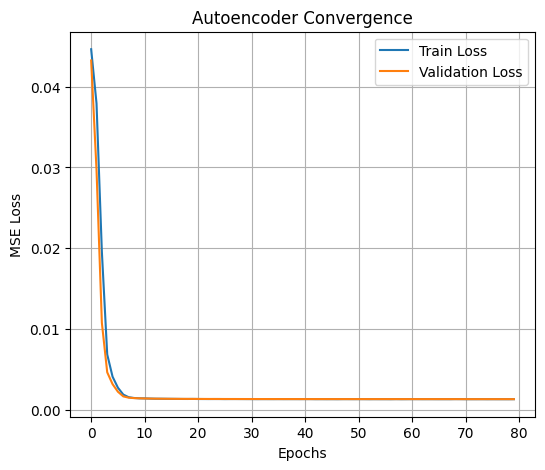

Autoencoder Evaluation Results
MCC            : 0.0000
TDR (Recall)   : 0.0000
PDR (FPR)      : 0.0000
AUC            : 0.9266
AUPR           : 0.1015


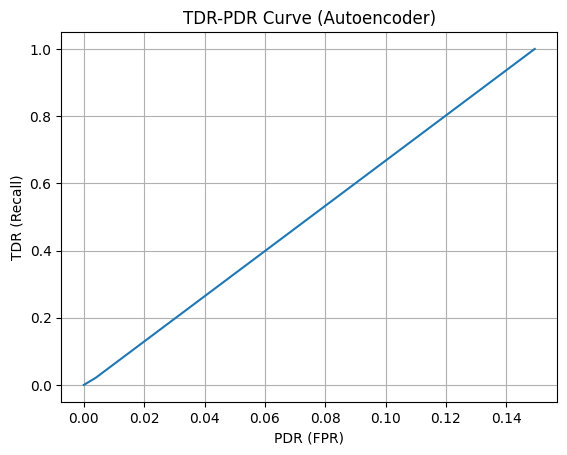

In [ ]:
# ============================================================
# UNDERCOMPLETE AUTOENCODER BASELINE WITH CONVERGENCE GRAPH
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix
import matplotlib.pyplot as plt
import ast

# ============================================================
# 1. DATA PROCESSOR
# ============================================================

class ProteinDataProcessor:
    def __init__(self):
        self.aa_vocab = {
            'A': 0, 'C': 1, 'D': 2, 'E': 3, 'F': 4, 'G': 5, 'H': 6, 'I': 7,
            'K': 8, 'L': 9, 'M': 10, 'N': 11, 'P': 12, 'Q': 13, 'R': 14,
            'S': 15, 'T': 16, 'V': 17, 'W': 18, 'Y': 19, 'X': 20
        }
        self.vocab_size = len(self.aa_vocab)

    def parse_data_file(self, file_path):
        sequences, labels, ids = [], [], []
        with open(file_path, 'r') as f:
            lines = f.readlines()
        i = 0
        while i < len(lines):
            if lines[i].startswith('>'):
                ids.append(lines[i][1:].strip())
                sequences.append(lines[i + 1].strip())
                labels.append(ast.literal_eval(lines[i + 2].strip()))
                i += 3
            else:
                i += 1
        return sequences, labels, ids

    def load_multiple_files(self, file_paths):
        S, L, I = [], [], []
        for path in file_paths:
            s, l, i = self.parse_data_file(path)
            S.extend(s); L.extend(l); I.extend(i)
        return S, L, I

    def create_one_hot(self, seq):
        x = np.zeros((len(seq), self.vocab_size))
        for i, a in enumerate(seq):
            x[i, self.aa_vocab.get(a, 20)] = 1
        return x

    def prepare_dataset(self, seqs, labels, max_len=None):
        if max_len is None:
            max_len = max(len(s) for s in seqs)
        X, Y, M = [], [], []
        for s, y in zip(seqs, labels):
            oh = self.create_one_hot(s)
            mask = [False]*len(s)
            if len(s) < max_len:
                pad = max_len - len(s)
                oh = np.vstack([oh, np.zeros((pad, self.vocab_size))])
                y = y + [0]*pad
                mask += [True]*pad
            X.append(oh); Y.append(y); M.append(mask)
        return np.array(X), np.array(Y), np.array(M)

# ============================================================
# 2. DATASET
# ============================================================

class ProteinSequenceDataset(Dataset):
    def __init__(self, X, y, masks):
        self.X = torch.FloatTensor(X)
        self.y = torch.FloatTensor(y)
        self.masks = torch.BoolTensor(masks)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return {'sequence': self.X[idx], 'label': self.y[idx], 'mask': self.masks[idx]}

# ============================================================
# 3. UNDERCOMPLETE AUTOENCODER
# ============================================================

class UndercompleteAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(input_dim, 128, 3, padding=1),
            nn.ReLU(),
            nn.Conv1d(128, latent_dim, 3, padding=1),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Conv1d(latent_dim, 128, 3, padding=1),
            nn.ReLU(),
            nn.Conv1d(128, input_dim, 3, padding=1),
            nn.Softmax(dim=1)
        )

    def forward(self, x):
        x = x.transpose(1, 2)
        z = self.encoder(x)
        recon = self.decoder(z)
        return recon.transpose(1, 2), z

# ============================================================
# 4. MASKED LOSS
# ============================================================

def masked_mse(recon, target, masks):
    recon = recon.reshape(-1, recon.shape[-1])
    target = target.reshape(-1, target.shape[-1])
    masks = masks.view(-1)
    valid = ~masks
    return nn.functional.mse_loss(recon[valid], target[valid])

# ============================================================
# 5. TRAINING FUNCTION WITH CONVERGENCE GRAPH
# ============================================================

def train_autoencoder(file_paths, epochs=40, batch_size=16, lr=1e-3):

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print("Device:", device)

    processor = ProteinDataProcessor()
    seqs, labels, _ = processor.load_multiple_files(file_paths)
    X, y, masks = processor.prepare_dataset(seqs, labels)

    Xtr, Xva, ytr, yva, mtr, mva = train_test_split(
        X, y, masks, test_size=0.2, random_state=42
    )

    train_loader = DataLoader(
        ProteinSequenceDataset(Xtr, ytr, mtr),
        batch_size=batch_size, shuffle=True
    )

    val_loader = DataLoader(
        ProteinSequenceDataset(Xva, yva, mva),
        batch_size=batch_size
    )

    model = UndercompleteAutoencoder(input_dim=processor.vocab_size, latent_dim=32).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    print("Model parameters:", sum(p.numel() for p in model.parameters()))

    best_val = float('inf')
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        tr_loss = 0
        for batch in train_loader:
            x = batch['sequence'].to(device)
            m = batch['mask'].to(device)

            optimizer.zero_grad()
            recon, _ = model(x)
            loss = masked_mse(recon, x, m)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item()
        tr_loss /= len(train_loader)
        train_losses.append(tr_loss)

        model.eval()
        va_loss = 0
        with torch.no_grad():
            for batch in val_loader:
                x = batch['sequence'].to(device)
                m = batch['mask'].to(device)
                recon, _ = model(x)
                va_loss += masked_mse(recon, x, m).item()
        va_loss /= len(val_loader)
        val_losses.append(va_loss)

        print(f"Epoch {epoch+1:02d} | Train MSE: {tr_loss:.6f} | Val MSE: {va_loss:.6f}")

        if va_loss < best_val:
            best_val = va_loss
            torch.save(model.state_dict(), "best_autoencoder.pt")

    print("Best validation reconstruction loss:", best_val)

    # Plot convergence
    plt.figure(figsize=(6,5))
    plt.plot(train_losses, label="Train Loss")
    plt.plot(val_losses, label="Validation Loss")
    plt.xlabel("Epochs")
    plt.ylabel("MSE Loss")
    plt.title("Autoencoder Convergence")
    plt.legend()
    plt.grid(True)
    plt.show()

    return model, val_loader, device

# ============================================================
# 6. EVALUATION FUNCTION
# ============================================================

def evaluate_autoencoder(model, data_loader, device, threshold=0.5):
    model.eval()
    y_true = []
    y_score = []

    with torch.no_grad():
        for batch in data_loader:
            x = batch['sequence'].to(device)
            y = batch['label'].cpu().numpy()
            mask = batch['mask'].cpu().numpy()
            recon, _ = model(x)
            recon = recon.cpu().numpy()
            error = np.mean((recon - x.cpu().numpy())**2, axis=-1)
            error[mask] = 0
            y_score.append(error)
            y_true.append(y)

    y_true = np.concatenate(y_true).flatten()
    y_score = np.concatenate(y_score).flatten()
    y_pred = (y_score > threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred)
    tp = cm[1,1]; fn = cm[1,0]; fp = cm[0,1]; tn = cm[0,0]
    mcc = matthews_corrcoef(y_true, y_pred)
    recall = tp/(tp+fn) if (tp+fn)>0 else 0
    fpr = fp/(fp+tn) if (fp+tn)>0 else 0
    auc = roc_auc_score(y_true, y_score)
    aupr = average_precision_score(y_true, y_score)

    print("Autoencoder Evaluation Results")
    print("========================================")
    print(f"MCC            : {mcc:.4f}")
    print(f"TDR (Recall)   : {recall:.4f}")
    print(f"PDR (FPR)      : {fpr:.4f}")
    print(f"AUC            : {auc:.4f}")
    print(f"AUPR           : {aupr:.4f}")

    # TDR-PDR Curve
    thresholds = np.linspace(0, y_score.max(), 100)
    tdr_list, pdr_list = [], []
    for t in thresholds:
        y_pred_t = (y_score > t).astype(int)
        cm_t = confusion_matrix(y_true, y_pred_t)
        tp_t = cm_t[1,1]; fn_t = cm_t[1,0]; fp_t = cm_t[0,1]; tn_t = cm_t[0,0]
        tdr_list.append(tp_t/(tp_t+fn_t) if (tp_t+fn_t)>0 else 0)
        pdr_list.append(fp_t/(fp_t+tn_t) if (fp_t+tn_t)>0 else 0)

    plt.plot(pdr_list, tdr_list)
    plt.xlabel("PDR (FPR)")
    plt.ylabel("TDR (Recall)")
    plt.title("TDR-PDR Curve (Autoencoder)")
    plt.grid(True)
    plt.show()

# ============================================================
# 7. RUN
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

if __name__ == "__main__":
    file_paths = [
        '/content/drive/MyDrive/443/RNA-577-Train.fasta',
        '/content/drive/MyDrive/443/RNA-142-Test.fasta',
        '/content/drive/MyDrive/443/DNA-735-Train.fasta',
        '/content/drive/MyDrive/443/DNA-180-Test.fasta'
    ]

    model, val_loader, device = train_autoencoder(file_paths, epochs=80, batch_size=32, lr=1e-3)
    evaluate_autoencoder(model, val_loader, device, threshold=0.5)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading data...
Total sequences loaded: 1634
Training residues: 385001
Validation residues: 96251
Step 1/10 | Train Loss: 1.0733 | Val Loss: 1.0621
Step 2/10 | Train Loss: 1.6799 | Val Loss: 1.6801
Step 3/10 | Train Loss: 1.9702 | Val Loss: 1.9655
Step 4/10 | Train Loss: 1.5958 | Val Loss: 1.5565
Step 5/10 | Train Loss: 1.6162 | Val Loss: 1.5868
Step 6/10 | Train Loss: 2.3697 | Val Loss: 2.3531
Step 7/10 | Train Loss: 1.6702 | Val Loss: 1.6705
Step 8/10 | Train Loss: 1.5643 | Val Loss: 1.5551
Step 9/10 | Train Loss: 1.5035 | Val Loss: 1.4816
Step 10/10 | Train Loss: 2.3203 | Val Loss: 2.3288


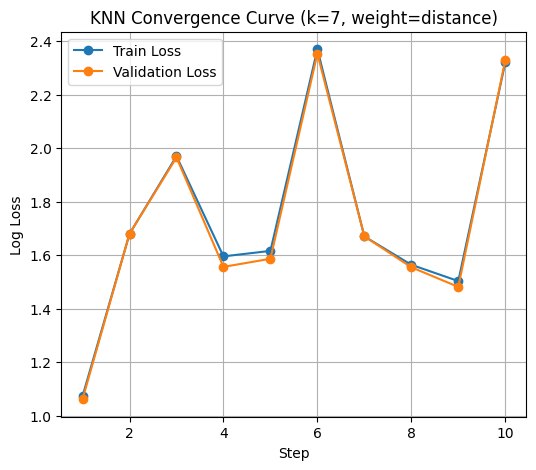


KNN Evaluation Results
MCC            : 0.0000
TDR (Recall)   : 0.0000
PDR (FPR)      : 0.0000
AUC            : 0.4867
AUPR           : 0.0941


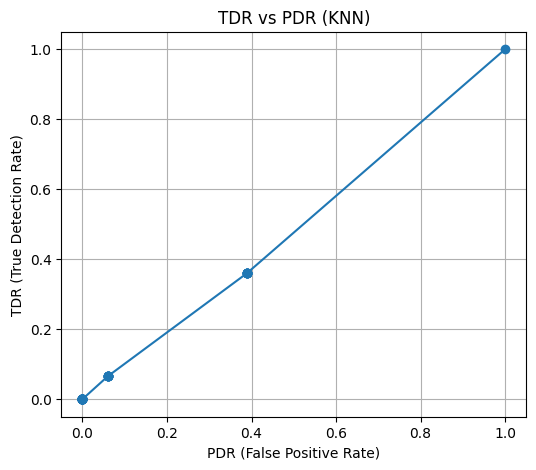

In [ ]:
import numpy as np
import ast
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    log_loss
)
import matplotlib.pyplot as plt

# 1. DATA PROCESSOR
# ===========================

from google.colab import drive
drive.mount('/content/drive')

class ProteinDataProcessor:
    """Processes protein/DNA/RNA sequence data with per-residue labels"""

    def __init__(self):
        self.aa_vocab = {
            'A': 0, 'C': 1, 'D': 2, 'E': 3, 'F': 4, 'G': 5, 'H': 6, 'I': 7,
            'K': 8, 'L': 9, 'M': 10, 'N': 11, 'P': 12, 'Q': 13, 'R': 14,
            'S': 15, 'T': 16, 'V': 17, 'W': 18, 'Y': 19, 'X': 20
        }
        self.vocab_size = len(self.aa_vocab)

    def parse_data_file(self, file_path):
        sequences, labels = [], []

        with open(file_path, "r") as f:
            lines = f.readlines()

        i = 0
        while i < len(lines):
            if lines[i].startswith(">"):
                seq = lines[i + 1].strip()
                label = ast.literal_eval(lines[i + 2].strip())

                if len(seq) == len(label):
                    sequences.append(seq)
                    labels.append(label)

                i += 3
            else:
                i += 1

        return sequences, labels

    def load_multiple_files(self, file_paths):
        all_sequences, all_labels = [], []

        for fp in file_paths:
            seqs, labs = self.parse_data_file(fp)
            all_sequences.extend(seqs)
            all_labels.extend(labs)

        print(f"Total sequences loaded: {len(all_sequences)}")
        return all_sequences, all_labels

    def encode_sequence(self, sequence):
        return [self.aa_vocab.get(aa, self.aa_vocab['X']) for aa in sequence]

    def create_one_hot(self, sequence):
        encoded = self.encode_sequence(sequence)
        one_hot = np.zeros((len(encoded), self.vocab_size))
        for i, idx in enumerate(encoded):
            one_hot[i, idx] = 1
        return one_hot

    def prepare_dataset(self, sequences, labels, max_length=None):
        if max_length is None:
            max_length = max(len(s) for s in sequences)

        X, y, masks = [], [], []

        for seq, lab in zip(sequences, labels):
            oh = self.create_one_hot(seq)
            mask = [False] * len(seq)

            if len(seq) < max_length:
                pad = max_length - len(seq)
                oh = np.vstack([oh, np.zeros((pad, self.vocab_size))])
                lab = lab + [0] * pad
                mask = mask + [True] * pad

            X.append(oh)
            y.append(lab)
            masks.append(mask)

        return np.array(X), np.array(y), np.array(masks)


# ===========================
# 2. RESIDUE-LEVEL DATASET
# ===========================

def prepare_knn_dataset(X, y, masks):
    """Flatten sequence data into residue-level samples"""
    X_flat, y_flat = [], []

    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            if not masks[i, j]:
                X_flat.append(X[i, j])
                y_flat.append(y[i, j])

    return np.array(X_flat), np.array(y_flat)


# ===========================
# 3. KNN MODEL
# ===========================

def build_knn_model(k=7):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=k,
            weights="distance",
            metric="euclidean"
        ))
    ])


# ===========================
# 4. EVALUATION
# ===========================

def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    tdr = tp / (tp + fn + 1e-8)
    pdr = fp / (fp + tn + 1e-8)
    mcc = matthews_corrcoef(y_true, y_pred)

    return {
        "MCC": mcc,
        "TDR (Recall)": tdr,
        "PDR (FPR)": pdr,
        "AUC": roc_auc_score(y_true, y_prob),
        "AUPR": average_precision_score(y_true, y_prob)
    }


def plot_tdr_pdr_curve(y_true, y_prob):
    thresholds = np.linspace(0, 1, 50)
    tdrs, pdrs = [], []

    for th in thresholds:
        y_pred = (y_prob >= th).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        tdrs.append(tp / (tp + fn + 1e-8))
        pdrs.append(fp / (fp + tn + 1e-8))

    plt.figure(figsize=(6, 5))
    plt.plot(pdrs, tdrs, marker="o")
    plt.xlabel("PDR (False Positive Rate)")
    plt.ylabel("TDR (True Detection Rate)")
    plt.title("TDR vs PDR (KNN)")
    plt.grid(True)
    plt.show()


# ===========================
# 5. KNN CONVERGENCE CURVE
# ===========================

def knn_train_with_convergence(X_train, y_train, X_val, y_val, k=7, weight='distance', n_steps=10):
    """
    Train KNN with repeated steps to simulate convergence,
    and plot Train vs Validation log loss.
    """
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, weights=weight, metric="euclidean"))
    ])

    tr_losses, va_losses = [], []

    for step in range(1, n_steps+1):
        # Shuffle training data
        idx = np.random.permutation(len(X_train))
        X_tr_step, y_tr_step = X_train[idx], y_train[idx]

        # Fit model
        model.fit(X_tr_step, y_tr_step)

        # Predict probabilities
        y_tr_prob = model.predict_proba(X_tr_step)[:, 1]
        y_va_prob = model.predict_proba(X_val)[:, 1]

        # Compute log loss
        tr_loss = log_loss(y_tr_step, y_tr_prob, labels=[0,1])
        va_loss = log_loss(y_val, y_va_prob, labels=[0,1])

        tr_losses.append(tr_loss)
        va_losses.append(va_loss)

        print(f"Step {step}/{n_steps} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f}")

    # Plot convergence
    plt.figure(figsize=(6,5))
    plt.plot(range(1, n_steps+1), tr_losses, label="Train Loss", marker="o")
    plt.plot(range(1, n_steps+1), va_losses, label="Validation Loss", marker="o")
    plt.xlabel("Step")
    plt.ylabel("Log Loss")
    plt.title(f"KNN Convergence Curve (k={k}, weight={weight})")
    plt.legend()
    plt.grid(True)
    plt.show()

    return model


# ===========================
# 6. MAIN PIPELINE
# ===========================

def main(file_paths, k=7):
    processor = ProteinDataProcessor()

    print("Loading data...")
    sequences, labels = processor.load_multiple_files(file_paths)

    X, y, masks = processor.prepare_dataset(sequences, labels)
    X_res, y_res = prepare_knn_dataset(X, y, masks)

    X_train, X_val, y_train, y_val = train_test_split(
        X_res, y_res,
        test_size=0.2,
        random_state=42,
        stratify=y_res
    )

    print(f"Training residues: {len(X_train)}")
    print(f"Validation residues: {len(X_val)}")

    # Train KNN with convergence curve
    model = knn_train_with_convergence(X_train, y_train, X_val, y_val, k=k, weight='distance', n_steps=10)

    # Evaluate final
    y_prob = model.predict_proba(X_val)[:, 1]
    results = compute_metrics(y_val, y_prob)

    print("\nKNN Evaluation Results")
    print("="*40)
    for k, v in results.items():
        print(f"{k:15s}: {v:.4f}")

    plot_tdr_pdr_curve(y_val, y_prob)


# ===========================
# 7. RUN
# ===========================

if __name__ == "__main__":
    file_paths = [
    '/content/drive/MyDrive/443 project/443/RNA-577-Train.fasta',
    '/content/drive/MyDrive/443 project/443/RNA-142-Test.fasta',
    '/content/drive/MyDrive/443 project/443/DNA-735-Train.fasta',
    '/content/drive/MyDrive/443 project/443/DNA-180-Test.fasta'
]

    main(file_paths, k=7)
